# Create a webspider and use it to analyze webpages

In [33]:
from urllib.request import urlopen
from bs4 import BeautifulSoup

html = urlopen("https://psychcentral.com/health/your-cat-depression-anxiety")
bs = BeautifulSoup(html, "html.parser")

## Webspider
Script that browses automatically the web by using the different links from webpages.

In [30]:
from urllib.request import urlopen
from urllib.error import HTTPError, URLError
from bs4 import BeautifulSoup

def gather_bs_from_url(url):
    try:
        html = urlopen(url)
        return BeautifulSoup(html, 'html.parser')
    except HTTPError as e:
        print(f"HTTP error: {e.code} - {e.reason}")
        return None 
    except URLError as e:
        print(f"URL error: {e.reason}")
        return None

bs = gather_bs_from_url("https://psychcentral.com/health/your-cat-depression-anxiety")

cleaned_links_from_page = list()
limit = 20
for link in bs.find_all('a'):
    # if link.attrs['href'] == 'https://www.psychcentral.com/' or link.attrs['href'] == 'https://www.psychcentral.com/conditions':
    #     continue
    if limit == 0:
        break

    # Remove references we can't use
    if 'href' in link.attrs:
        if not link.attrs.get('href', '').startswith('#'):
            cleaned_links_from_page.append(link.attrs['href'])
        # print(link.attrs['href'])
    limit -= 1

In [32]:
cleaned_links_from_page

['https://www.psychcentral.com/',
 'https://www.psychcentral.com/conditions',
 'https://www.psychcentral.com/addictions',
 'https://www.psychcentral.com/anxiety',
 'https://www.psychcentral.com/adhd',
 'https://www.psychcentral.com/bipolar',
 'https://www.psychcentral.com/depression',
 'https://www.psychcentral.com/ptsd',
 'https://www.psychcentral.com/schizophrenia',
 'https://www.psychcentral.com/disorders/disorders',
 'https://www.psychcentral.com/disorders/adjustment-disorder-symptoms',
 'https://www.psychcentral.com/anxiety/agoraphobia-symptoms',
 'https://www.psychcentral.com/disorders/antisocial-personality-disorder',
 'https://www.psychcentral.com/disorders/borderline-personality-disorder',
 'https://www.psychcentral.com/childhood-adhd/childhood-adhd',
 'https://www.psychcentral.com/disorders/dissociative-identity-disorder',
 'https://www.psychcentral.com/disorders/narcissistic-personality-disorder',
 'https://www.psychcentral.com/disorders/narcolepsy-symptoms',
 'https://www.p

### Get and clean text
There are many links that only collect other links, so I drop all articles where the text is smaller than 100 letters.

In [225]:
# use these links to collect all the h1,h2,h3,paragraph texts.
_
## There is a repeating header for all links, let's remove them
skip_texts = {'Featured', 'Articles', 'Wellness Topics', 'Original Series', 'News & Events', 'Podcasts', 'Conditions', 'Lifestyle', 'Treatment & Support',
              'Ready to start therapy? Our Find a Therapist resource may help.'}

one_text_per_url_dict = {}

for url in cleaned_links_from_page:
    bs = gather_bs_from_ur(url)
    one_text_per_url_dict[url] = ""

    for tag in bs.find_all(tags):
        if tag.get_text() in skip_texts:
            continue
        if tag.has_attr('class'):
            if any('css' in cls for cls in tag.attrs['class']):
                continue 
        one_text_per_url_dict[url] += tag.get_text()
    
    if len(one_text_per_url_dict[url]) < 100:
        del one_text_per_url_dict[url]

In [7]:
bs = gather_bs_from_url("https://psychcentral.com/health/your-cat-depression-anxiety")
h2tags = bs.find_all('h2')
if len(h2tags) >= 3:
    print(h2tags[2].get_text())

Cats also face mental health issues


In [28]:
import re

## Get the same with regular expressions
h2tags = re.findall(r'<h2.*?>.*?</h2>', bs.prettify(), re.DOTALL)
if len(h2tags) >= 3:
    print(h2tags[2])

<h2>
              <div>
               <a class="chartbeat-section" name="mental-health-of-cats">
                Cats also face mental health issues
               </a>
              </div>
             </h2>


In [226]:
len(one_text_per_url_dict)

14

## NLP calculations

Before I do any calculation, I need to lemmatize the collected words

In [228]:
import nltk
# nltk.download('wordnet')
# nltk.download('punkt')
# nltk.download('stopwords')

In [266]:
import re
from nltk.corpus import stopwords
from nltk.stem import  WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

# Preprocessing the texs
lemmatized_words_per_link = {}
for url in one_text_per_url_dict.keys():
    text = one_text_per_url_dict[url]
    # Standardize to lower case
    text = text.lower()

    # Tokenize + Remove stop words
    tokens = nltk.tokenize.word_tokenize(text)
    text = [word for word in [re.sub(r'[^a-zA-Z0-9]', '', word) for word in tokens] if word and word not in stopwords.words()]

    # Remove stop words
    # text = [word for word in text if not word in stopwords.words()]

    # Lemmatize
    lemmatized_words_per_link[url] = [lemmatizer.lemmatize(word) for word in text]

In [ ]:
#lemmatized_words_per_link

Summary for https://www.psychcentral.com/addictions:
<FreqDist with 392 samples and 666 outcomes>
3 most common word:
[('substance', 29), ('disorder', 24), ('addiction', 20)]
The positivity of the article:0.9962
Very Positive


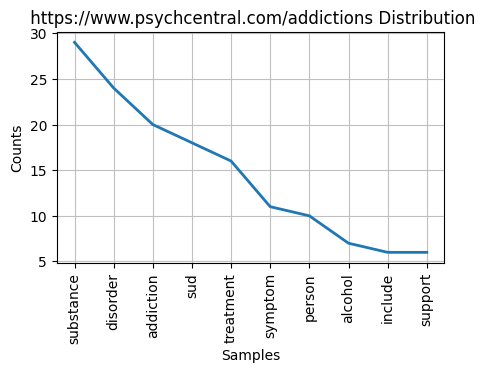

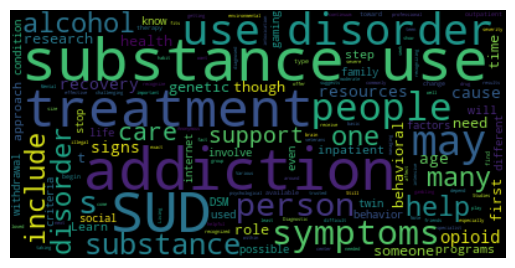



Summary for https://www.psychcentral.com/disorders/disorders:
<FreqDist with 306 samples and 547 outcomes>
3 most common word:
[('disorder', 46), ('mental', 25), ('health', 23)]
The positivity of the article:0.7636
Very Positive


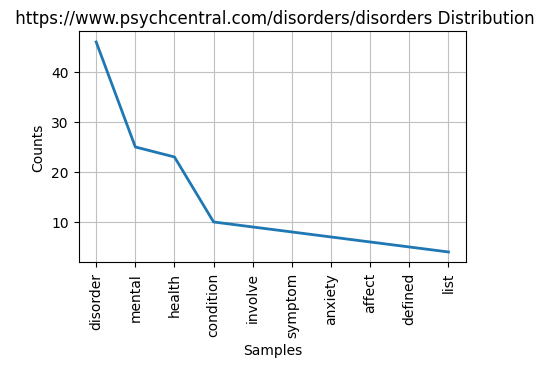

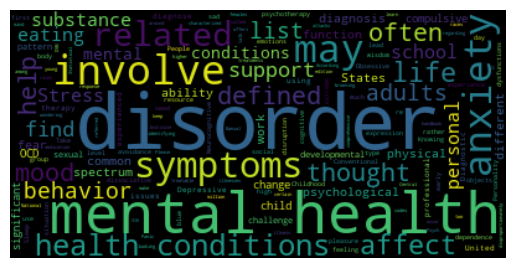



Summary for https://www.psychcentral.com/disorders/adjustment-disorder-symptoms:
<FreqDist with 266 samples and 486 outcomes>
3 most common word:
[('disorder', 30), ('adjustment', 27), ('type', 16)]
The positivity of the article:-0.9994
Very Negative


Summary for https://www.psychcentral.com/anxiety/agoraphobia-symptoms:
<FreqDist with 355 samples and 589 outcomes>
3 most common word:
[('anxiety', 25), ('agoraphobia', 21), ('symptom', 16)]
The positivity of the article:-0.9995
Very Negative


Summary for https://www.psychcentral.com/disorders/antisocial-personality-disorder:
<FreqDist with 385 samples and 760 outcomes>
3 most common word:
[('aspd', 44), ('disorder', 37), ('personality', 25)]
The positivity of the article:-0.996
Very Negative


Summary for https://www.psychcentral.com/disorders/borderline-personality-disorder:
<FreqDist with 436 samples and 783 outcomes>
3 most common word:
[('bpd', 36), ('disorder', 28), ('personality', 24)]
The positivity of the article:-0.9982
Ver

In [287]:
from nltk.probability import FreqDist
import matplotlib.pyplot as plt
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from wordcloud import WordCloud

#nltk.download('vader_lexicon')
analyzer=SentimentIntensityAnalyzer()

# Create summaries for the pages, but only plot 2
for i, url in enumerate(lemmatized_words_per_link):
    tokens = lemmatized_words_per_link[url]
    print(f'Summary for {url}:')

    # Frequencies
    f_dist = FreqDist(tokens)
    print(f_dist)
    print(f"3 most common word:")
    print (f_dist.most_common(3))

    # Sentiment analysis
    compound = float(analyzer.polarity_scores(one_text_per_url_dict[url])['compound'])
    print(f"The positivity of the article:{compound}")

    if compound <= -0.5:
        print("Very Negative")
    elif -0.5 < compound <= -0.1:
        print("Negative")
    elif -0.1 < compound <= 0.1:
        print("Neutral")
    elif 0.1 < compound <= 0.5:
        print("Positive")
    elif 0.5 < compound:
        print("Very Positive")

    # Create just limited number plots:
    if i < 2:
        ## diagram for the 10 most common words
        plt.figure(figsize=(5,3))
        fd = nltk.FreqDist(dict(f_dist.most_common(10)))
        fd.plot(10, cumulative=False, title=f" {url} Distribution", label=f'Plot {i}')
        plt.show()
        
        ## wordcloud
        wordcloud = WordCloud().generate(one_text_per_url_dict[url])
        plt.imshow(wordcloud, interpolation='bilinear')
        plt.axis("off")
        plt.show()


    print("\n")
        